In [1]:
import tensorflow as tf
print(tf.__version__)

2.21.0


In [2]:
import warnings
warnings.filterwarnings('ignore')

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    import IPython
    working_directory = "/".join(
            IPython.extract_module_locals()[1]["__vsc_ipynb_file__"].split("/")[:-1]
        )
    print("Setting working directory to: ", working_directory)
    print(os.chdir(working_directory))
except Exception as e:
    print("It was impossible to set your directory as the current one because of the following message")
    print(e)
    print("The working directory is: ", os.getcwd())

from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, roc_auc_score, roc_curve
from sklearn.preprocessing import StandardScaler

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models, regularizers
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
import tensorflow.keras.backend as K

# Reproducibility
np.random.seed(42)
tf.random.set_seed(42)

print("="*70)
print("FINAL TESS CLASSIFICATION")
print("="*70)

# # Optional: make TF less eager to pre-allocate all GPU memory (if using GPU)
# try:
#     gpus = tf.config.experimental.list_physical_devices('GPU')
#     for gpu in gpus:
#         tf.config.experimental.set_memory_growth(gpu, True)
#     if gpus:
#         print(f"Enabled memory growth for {len(gpus)} GPU(s).")
# except Exception as e:
#     print("GPU setup note:", e)

# print("TF version:", tf.__version__)


It was impossible to set your directory as the current one because of the following message
'__vsc_ipynb_file__'
The working directory is:  /Users/dhitidoddamreddy/Desktop/year_2/ca2026/comp_astro_26
FINAL TESS CLASSIFICATION


In [3]:
def focal_loss(gamma=2.5, alpha=0.75):
    """Focal loss optimized for severe imbalance (binary)."""
    def focal_loss_fixed(y_true, y_pred):
        epsilon = K.epsilon()
        y_pred = K.clip(y_pred, epsilon, 1.0 - epsilon)
        
        pt = tf.where(tf.equal(y_true, 1), y_pred, 1 - y_pred)
        alpha_factor = tf.where(tf.equal(y_true, 1), alpha, 1 - alpha)
        focal_weight = alpha_factor * K.pow(1 - pt, gamma)
        bce = -K.log(pt)
        return K.mean(focal_weight * bce)
    return focal_loss_fixed


In [4]:
def create_balanced_dataset(X, y, samples_per_class=400):
    """Create a perfectly balanced dataset via lightweight augmentations."""
    print("\n" + "="*70)
    print("CREATING BALANCED DATASET")
    print("="*70)
    
    X_class0 = X[y == 0]
    X_class1 = X[y == 1]
    
    print(f"Original - Class 0: {len(X_class0)}, Class 1: {len(X_class1)}")
    
    def augment_to_target(X_orig, n_target):
        if len(X_orig) >= n_target:
            idx = np.random.choice(len(X_orig), n_target, replace=False)
            return X_orig[idx]
        
        X_result = [X_orig]
        while len(np.vstack(X_result)) < n_target:
            # number we still need (cap to avoid oversampling too big chunks)
            n_needed = n_target - len(np.vstack(X_result))
            idx = np.random.choice(len(X_orig), min(len(X_orig), n_needed))
            
            aug_type = np.random.rand()
            if aug_type < 0.25:
                # Additive Gaussian noise
                X_aug = X_orig[idx] + np.random.normal(0, 0.01, (len(idx), X_orig.shape[1]))
            elif aug_type < 0.5:
                # Multiplicative scaling
                scale = 1.0 + np.random.uniform(-0.03, 0.03, (len(idx), 1))
                X_aug = X_orig[idx] * scale
            elif aug_type < 0.75:
                # Circular shift (time shift)
                shifts = np.random.randint(-20, 20, len(idx))
                X_aug = np.array([np.roll(X_orig[i], s) for i, s in zip(idx, shifts)])
            else:
                # Mild combo: small scale + small noise
                X_aug = X_orig[idx] * (1.0 + np.random.uniform(-0.02, 0.02, (len(idx), 1)))
                X_aug += np.random.normal(0, 0.008, X_aug.shape)
            
            X_result.append(X_aug)
        
        X_final = np.vstack(X_result)
        return X_final[:n_target]
    
    X0_bal = augment_to_target(X_class0, samples_per_class)
    X1_bal = augment_to_target(X_class1, samples_per_class)
    
    print(f"Balanced - Class 0: {len(X0_bal)}, Class 1: {len(X1_bal)}")
    
    X_balanced = np.vstack([X0_bal, X1_bal])
    y_balanced = np.concatenate([np.zeros(samples_per_class), np.ones(samples_per_class)])
    
    # Shuffle
    idx = np.arange(len(X_balanced))
    np.random.shuffle(idx)
    
    return X_balanced[idx], y_balanced[idx]


In [5]:
def load_data(csv_path='/data/tess_data.csv', n_bins=1000):
    """Load CSV, split, balance train set, and standardize features."""
    print("\n" + "="*70)
    print("LOADING DATA")
    print("="*70)
    
    df = pd.read_csv(csv_path)
    print(f"Dataset: {df.shape[0]} samples")
    
    flux_cols = [f'flux_{i:04d}' for i in range(n_bins)]
    flux_err_cols = [f'flux_err_{i:04d}' for i in range(n_bins)]
    X = df[flux_cols].values
    X_err = df[flux_err_cols].values
    y = df['label'].values
    
    metadata_cols = ['toi_name', 'tic', 'label', 'disp', 'period_d', 't0_bjd', 'dur_hr', 'sector']
    metadata = df[metadata_cols]
    
    print("\nOriginal distribution:")
    print(f"  Class 0: {(y==0).sum()}, Class 1: {(y==1).sum()}")
    if (y==0).sum() > 0:
        print(f"  Ratio: {(y==1).sum() / (y==0).sum():.2f}:1")
    
    # Train/test split (keep errors aligned; stratify to preserve class ratio)
    X_train, X_test, y_train, y_test, X_err_train, X_err_test, idx_train, idx_test = train_test_split(
        X, y, X_err, np.arange(len(y)),
        test_size=0.2,
        random_state=42,
        stratify=y
    )
    
    print(f"\nInitial split - Train: {len(X_train)}, Test: {len(X_test)}")
    
    # Balance training set
    X_train, y_train = create_balanced_dataset(X_train, y_train, samples_per_class=350)
    
    # Standardize (fit on train, apply to test)
    print("\n" + "="*70)
    print("STANDARDIZATION")
    print("="*70)
    
    scaler = StandardScaler()
    X_train = scaler.fit_transform(X_train)
    X_test = scaler.transform(X_test)
    
    print(f"Train: mean={X_train.mean():.6f}, std={X_train.std():.6f}")
    print(f"Test:  mean={X_test.mean():.6f}, std={X_test.std():.6f}")
    
    # Reshape for Conv1D: (samples, timesteps, channels)
    X_train = X_train.reshape(-1, n_bins, 1)
    X_test = X_test.reshape(-1, n_bins, 1)
    
    metadata_test = metadata.iloc[idx_test].reset_index(drop=True)
    
    print(f"\nFinal - X_train: {X_train.shape}, X_test: {X_test.shape}")
    print(f"Train dist: 0={( y_train==0).sum()}, 1={(y_train==1).sum()}")
    
    # Return standardized test for model input, but also return the standardized
    # copy (X_test_orig) so we can inverse-transform for plotting with error bars.
    return X_train, X_test, y_train, y_test, metadata_test, X_test.copy(), X_err_test, scaler


In [6]:
def build_simple_cnn(n_bins=1000):
    """Simpler CNN to prevent overfitting on small datasets."""
    print("\n" + "="*70)
    print("BUILDING SIMPLIFIED CNN")
    print("="*70)
    
    model = models.Sequential([
        layers.Input(shape=(n_bins, 1)),
        
        # Feature extraction
        layers.Conv1D(64, kernel_size=3, padding='same', activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling1D(2),
        layers.Dropout(0.3),
        
        layers.Conv1D(128, kernel_size=3, padding='same', activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling1D(2),
        layers.Dropout(0.3),
        
        layers.Conv1D(256, kernel_size=3, padding='same', activation='relu'),
        layers.BatchNormalization(),
        layers.GlobalAveragePooling1D(),
        layers.Dropout(0.4),
        
        # Classification head
        layers.Dense(512, activation='relu', kernel_regularizer=regularizers.l2(0.001)),
        layers.Dropout(0.2),
        layers.Dense(256, activation='relu', kernel_regularizer=regularizers.l2(0.001)),
        layers.Dropout(0.2),
        layers.Dense(128, activation='relu', kernel_regularizer=regularizers.l2(0.001)),
        layers.Dropout(0.2),
        
        layers.Dense(1, activation='sigmoid')
    ])
    
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.0005),
        loss=focal_loss(gamma=2.5, alpha=0.75),
        metrics=['accuracy',
                 keras.metrics.Precision(name='precision'),
                 keras.metrics.Recall(name='recall'),
                 keras.metrics.AUC(name='auc')]
    )
    
    model.summary()
    print("\nUsing Focal Loss (gamma=2.5, alpha=0.75)")
    return model


In [7]:
def train_model(model, X_train, y_train, X_val, y_val, epochs=100):
    """Train the model with AUC-centric callbacks."""
    print("\n" + "="*70)
    print("TRAINING")
    print("="*70)
    
    callbacks = [
        EarlyStopping(
            monitor='val_auc',
            patience=20,
            restore_best_weights=True,
            mode='max',
            verbose=1
        ),
        ReduceLROnPlateau(
            monitor='val_auc',
            factor=0.5,
            patience=8,
            min_lr=1e-7,
            mode='max',
            verbose=1
        ),
        ModelCheckpoint(
            'best_model_final.keras',
            monitor='val_auc',
            save_best_only=True,
            mode='max',
            verbose=1
        )
    ]
    
    history = model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=epochs,
        batch_size=32,
        callbacks=callbacks,
        verbose=1
    )
    return history


In [8]:
def evaluate_with_optimal_threshold(model, X_test, y_test):
    """Find an optimal threshold from ROC (Youden's J) and evaluate."""
    print("\n" + "="*70)
    print("THRESHOLD OPTIMIZATION & EVALUATION")
    print("="*70)
    
    y_pred_proba = model.predict(X_test, verbose=0).flatten()
    fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba)
    
    # Youden's J statistic
    j_scores = tpr - fpr
    optimal_idx = np.argmax(j_scores)
    optimal_threshold = thresholds[optimal_idx]
    
    print(f"\nOptimal threshold: {optimal_threshold:.4f} (default=0.5)")
    print(f"  At this threshold: TPR={tpr[optimal_idx]:.4f}, FPR={fpr[optimal_idx]:.4f}")
    
    # Predictions with optimal vs default thresholds
    y_pred_optimal = (y_pred_proba >= optimal_threshold).astype(int)
    y_pred_default = (y_pred_proba >= 0.5).astype(int)
    
    # Metrics
    acc_optimal = accuracy_score(y_test, y_pred_optimal)
    acc_default = accuracy_score(y_test, y_pred_default)
    auc = roc_auc_score(y_test, y_pred_proba)
    
    print("\nResults:")
    print(f"  AUC-ROC: {auc:.4f}")
    print(f"  Accuracy (default threshold=0.5): {acc_default:.4f} ({acc_default*100:.2f}%)")
    print(f"  Accuracy (optimal threshold={optimal_threshold:.4f}): {acc_optimal:.4f} ({acc_optimal*100:.2f}%)")
    
    print("\nWith optimal threshold:")
    print(classification_report(y_test, y_pred_optimal,
                                target_names=['Non-Planet', 'Planet'],
                                digits=4,
                                zero_division=0))
    
    print("\nPrediction distribution (optimal threshold):")
    print(f"  Predicted 0: {(y_pred_optimal == 0).sum()}")
    print(f"  Predicted 1: {(y_pred_optimal == 1).sum()}")
    print("True distribution:")
    print(f"  True 0: {(y_test == 0).sum()}")
    print(f"  True 1: {(y_test == 1).sum()}")
    
    return y_pred_optimal, y_pred_proba, optimal_threshold


In [9]:
def plot_lightcurves_with_predictions(X_test_orig, X_err_test, y_test, y_pred, y_pred_proba, 
                                       metadata_test, scaler, threshold, n_samples=6,
                                       save_path='sample_lightcurves_predictions.png'):
    """Plot light curves with error bars and prediction info; save to file."""
    print("\n" + "="*70)
    print(f"PLOTTING LIGHTCURVES WITH PREDICTIONS (n={n_samples})")
    print("="*70)
    
    n_samples = min(n_samples, len(X_test_orig))
    
    # Select diverse samples: correct/incorrect for both classes
    correct_planet = np.where((y_test == 1) & (y_pred == 1))[0]
    incorrect_planet = np.where((y_test == 1) & (y_pred == 0))[0]
    correct_nonplanet = np.where((y_test == 0) & (y_pred == 0))[0]
    incorrect_nonplanet = np.where((y_test == 0) & (y_pred == 1))[0]
    
    selected_idx = []
    per_category = max(1, n_samples // 4)
    
    for idx_list in [correct_planet, incorrect_planet, correct_nonplanet, incorrect_nonplanet]:
        if len(idx_list) > 0:
            n_select = min(per_category, len(idx_list))
            selected_idx.extend(np.random.choice(idx_list, n_select, replace=False))
    
    while len(selected_idx) < n_samples:
        remaining = list(set(range(len(y_test))) - set(selected_idx))
        if remaining:
            selected_idx.append(np.random.choice(remaining))
        else:
            break
    
    selected_idx = np.array(selected_idx[:n_samples])
    
    # Figure layout
    n_cols = 2
    n_rows = (n_samples + n_cols - 1) // n_cols
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 4*n_rows))
    if n_samples == 1:
        axes = np.array([axes])
    axes = axes.flatten()
    
    for plot_i, idx in enumerate(selected_idx):
        ax = axes[plot_i]
        
        # Inverse transform to original scale for plotting
        flux_norm = X_test_orig[idx].flatten()
        flux_err = X_err_test[idx]
        flux_original = scaler.inverse_transform(flux_norm.reshape(1, -1)).flatten()
        
        time_bins = np.arange(len(flux_original))
        
        # Metadata
        toi_name = metadata_test.loc[idx, 'toi_name']
        tic = metadata_test.loc[idx, 'tic']
        disp = metadata_test.loc[idx, 'disp']
        sector = metadata_test.loc[idx, 'sector']
        
        true_label = y_test[idx]
        pred_label = y_pred[idx]
        pred_prob = y_pred_proba[idx]
        
        is_correct = (true_label == pred_label)
        true_str = 'Transit' if true_label == 1 else 'Non-Transit'
        pred_str = 'Transit' if pred_label == 1 else 'Non-Transit'
        
        # Errorbar plot
        ax.errorbar(time_bins, flux_original, yerr=flux_err, fmt='o', markersize=2,
                    ecolor='gray', elinewidth=0.5, capsize=0, alpha=0.6, label='Data')
        
        # Baseline median
        baseline = np.median(flux_original)
        ax.axhline(baseline, linestyle='--', linewidth=1, alpha=0.7, label='Baseline')
        
        ax.set_xlabel('Time Bin', fontsize=10, fontweight='bold')
        ax.set_ylabel('Flux (original scale)', fontsize=10, fontweight='bold')
        ax.grid(True, alpha=0.3)
        ax.legend(loc='upper right', fontsize=8)
        
        status_symbol = '✓' if is_correct else '✗'
        color = 'green' if is_correct else 'red'
        title = (f'TOI {toi_name} (TIC {tic}, {disp}) - TESS Sector {sector}\n'
                 f'True: {true_str} | Pred: {pred_str} (p={pred_prob:.3f}) {status_symbol}')
        ax.set_title(title, fontsize=10, fontweight='bold', color=color, pad=10)
        
        for spine in ax.spines.values():
            spine.set_edgecolor(color)
            spine.set_linewidth(2.0)
    
    # Hide unused axes
    for j in range(n_samples, len(axes)):
        axes[j].axis('off')
    
    plt.suptitle(f'Sample Light-curve Predictions (Threshold={threshold:.3f})',
                 fontsize=14, fontweight='bold', y=0.995)
    plt.tight_layout()
    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    print(f"Saved: {save_path}")
    plt.close()


def plot_all(y_test, y_pred, y_pred_proba, history, metadata_test, X_test, threshold,
             X_test_orig=None, X_err_test=None, scaler=None):
    """Create and save confusion matrix and training curves. Optionally plot light curves."""
    print("\n" + "="*70)
    print("VISUALIZATIONS")
    print("="*70)
    
    # Confusion matrix (Matplotlib-only)
    cm = confusion_matrix(y_test, y_pred)
    fig, ax = plt.subplots(figsize=(8, 6))
    im = ax.imshow(cm, interpolation='nearest', cmap='Blues')
    ax.figure.colorbar(im, ax=ax)
    ax.set(xticks=np.arange(2),
           yticks=np.arange(2),
           xticklabels=['Non-Planet', 'Planet'],
           yticklabels=['Non-Planet', 'Planet'],
           xlabel='Predicted', ylabel='True',
           title=f'Confusion Matrix (threshold={threshold:.3f})')
    
    # Add counts and percentages
    total = cm.sum()
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            count = cm[i, j]
            pct = (count / total * 100) if total > 0 else 0.0
            ax.text(j, i, f"{count}\n({pct:.1f}%)", ha='center', va='center', color='black', fontsize=10)
    
    plt.tight_layout()
    plt.savefig('confusion_matrix_final.png', dpi=300)
    print("Saved: confusion_matrix_final.png")
    plt.close()
    
    # Training history
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))
    metrics = [('loss', 'Loss'), ('accuracy', 'Accuracy'),
               ('auc', 'AUC'), ('recall', 'Recall')]
    
    for idx, (metric, title) in enumerate(metrics):
        ax = axes[idx // 2, idx % 2]
        if metric in history.history and f'val_{metric}' in history.history:
            ax.plot(history.history[metric], label='Train', linewidth=2)
            ax.plot(history.history[f'val_{metric}'], label='Val', linewidth=2)
            ax.set_xlabel('Epoch')
            ax.set_ylabel(title)
            ax.set_title(f'{title} vs Epoch', fontweight='bold')
            ax.legend()
            ax.grid(alpha=0.3)
    
    plt.suptitle('Training History - Final Model', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.savefig('training_history_final.png', dpi=300)
    print("Saved: training_history_final.png")
    plt.close()
    
    # Optional: light-curve panel
    if X_test_orig is not None and X_err_test is not None and scaler is not None:
        plot_lightcurves_with_predictions(X_test_orig, X_err_test, y_test, y_pred, 
                                          y_pred_proba, metadata_test, scaler, threshold, n_samples=6)


In [10]:
# Path to your dataset
CSV_PATH = './data/tess_data.csv'   # <- change me if needed
N_BINS = 1000                # number of flux bins/columns per sample


In [11]:
# 1) Load and prepare data
X_train, X_test, y_train, y_test, metadata_test, X_test_orig, X_err_test, scaler = load_data(
    csv_path=CSV_PATH, n_bins=N_BINS
)


LOADING DATA
Dataset: 944 samples

Original distribution:
  Class 0: 472, Class 1: 472
  Ratio: 1.00:1

Initial split - Train: 755, Test: 189

CREATING BALANCED DATASET
Original - Class 0: 377, Class 1: 378
Balanced - Class 0: 350, Class 1: 350

STANDARDIZATION
Train: mean=-0.000000, std=1.000000
Test:  mean=-0.001916, std=0.463545

Final - X_train: (700, 1000, 1), X_test: (189, 1000, 1)
Train dist: 0=350, 1=350


In [12]:
# 2) Build model
model = build_simple_cnn(n_bins=N_BINS)


BUILDING SIMPLIFIED CNN


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 1000, 64)       │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 1000, 64)       │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 500, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 500, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 500, 128)       │        24,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 500, 128)       │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 250, 128)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 250, 128)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_2 (Conv1D)               │ (None, 250, 256)       │        98,560 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 250, 256)       │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │       131,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 421,249 (1.61 MB)

 Trainable params: 420,353 (1.60 MB)

 Non-trainable params: 896 (3.50 KB)


Using Focal Loss (gamma=2.5, alpha=0.75)


In [13]:
# 3) Train
history = train_model(model, X_train, y_train, X_test, y_test, epochs=200)


TRAINING
Epoch 1/200
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step - accuracy: 0.5286 - auc: 0.5287 - loss: 0.8357 - precision: 0.5169 - recall: 0.8743
Epoch 1: val_auc improved from None to 0.54412, saving model to best_model_final.keras

Epoch 1: finished saving model to best_model_final.keras
22/22 ━━━━━━━━━━━━━━━━━━━━ 2s 54ms/step - accuracy: 0.5286 - auc: 0.5287 - loss: 0.8357 - precision: 0.5169 - recall: 0.8743 - val_accuracy: 0.4974 - val_auc: 0.5441 - val_loss: 0.7589 - val_precision: 0.4974 - val_recall: 1.0000 - learning_rate: 5.0000e-04
Epoch 2/200
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step - accuracy: 0.5300 - auc: 0.5166 - loss: 0.7017 - precision: 0.5160 - recall: 0.9686
Epoch 2: val_auc improved from 0.54412 to 0.59871, saving model to best_model_final.keras

Epoch 2: finished saving model to best_model_final.keras
22/22 ━━━━━━━━━━━━━━━━━━━━ 1s 49ms/step - accuracy: 0.5300 - auc: 0.5166 - loss: 0.7017 - precision: 0.5160 - recall: 0.9686 - val_accuracy: 0.4974 - val_auc: 0.5987

In [14]:
# 4) Evaluate with optimal threshold
y_pred, y_pred_proba, threshold = evaluate_with_optimal_threshold(model, X_test, y_test)


THRESHOLD OPTIMIZATION & EVALUATION

Optimal threshold: 0.4904 (default=0.5)
  At this threshold: TPR=0.8830, FPR=0.1474

Results:
  AUC-ROC: 0.8900
  Accuracy (default threshold=0.5): 0.8307 (83.07%)
  Accuracy (optimal threshold=0.4904): 0.8677 (86.77%)

With optimal threshold:
              precision    recall  f1-score   support

  Non-Planet     0.8804    0.8526    0.8663        95
      Planet     0.8557    0.8830    0.8691        94

    accuracy                         0.8677       189
   macro avg     0.8681    0.8678    0.8677       189
weighted avg     0.8681    0.8677    0.8677       189


Prediction distribution (optimal threshold):
  Predicted 0: 92
  Predicted 1: 97
True distribution:
  True 0: 95
  True 1: 94


In [15]:
# 5) Visualize & save artifacts
plot_all(y_test, y_pred, y_pred_proba, history, metadata_test, X_test, threshold,
         X_test_orig=X_test_orig, X_err_test=X_err_test, scaler=scaler)

# Persist model and threshold
model.save('tess_model_final.keras')
np.save('optimal_threshold.npy', threshold)

print("\n" + "="*70)
print("TRAINING COMPLETE!")
print("="*70)
print("\nKey improvements:")
print("  ✓ Perfectly balanced training data")
print("  ✓ Focal loss for hard examples")
print("  ✓ Optimal threshold selection")
print("  ✓ AUC-focused optimization")
print("\nFiles:")
print("  - tess_model_final.keras")
print("  - best_model_final.keras")
print("  - optimal_threshold.npy")
print("  - confusion_matrix_final.png")
print("  - training_history_final.png")
print("  - sample_lightcurves_predictions.png")
print("="*70)


VISUALIZATIONS
Saved: confusion_matrix_final.png
Saved: training_history_final.png

PLOTTING LIGHTCURVES WITH PREDICTIONS (n=6)
Saved: sample_lightcurves_predictions.png

TRAINING COMPLETE!

Key improvements:
  ✓ Perfectly balanced training data
  ✓ Focal loss for hard examples
  ✓ Optimal threshold selection
  ✓ AUC-focused optimization

Files:
  - tess_model_final.keras
  - best_model_final.keras
  - optimal_threshold.npy
  - confusion_matrix_final.png
  - training_history_final.png
  - sample_lightcurves_predictions.png


In [16]:
from sklearn.metrics import precision_score
print(confusion_matrix(y_test, y_pred))
print("Precision (Planet):", precision_score(y_test, y_pred))
model.summary()

[[81 14]
 [11 83]]
Precision (Planet): 0.8556701030927835


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 1000, 64)       │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 1000, 64)       │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 500, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 500, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 500, 128)       │        24,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 500, 128)       │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 250, 128)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 250, 128)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_2 (Conv1D)               │ (None, 250, 256)       │        98,560 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 250, 256)       │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │       131,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,261,957 (4.81 MB)

 Trainable params: 420,353 (1.60 MB)

 Non-trainable params: 896 (3.50 KB)

 Optimizer params: 840,708 (3.21 MB)

In [22]:
# from sklearn.metrics import precision_score

# REPORT = 'report_cnn_assignment2_taskF.txt'

# def write_report(name, params, model, y_test, y_pred, threshold, mode='a'):
#     cm = confusion_matrix(y_test, y_pred)
#     prec = precision_score(y_test, y_pred)
#     lines = []
#     model.summary(print_fn=lines.append)
#     with open(REPORT, mode) as f:
#         f.write("=" * 70 + "\n")
#         f.write(f"{name}\n")
#         f.write(f"Hyperparameters: {params}\n")
#         f.write(f"Optimal threshold: {threshold:.4f}\n\n")
#         f.write("Architecture:\n" + "\n".join(lines) + "\n\n")
#         f.write("Confusion matrix (rows=true, cols=predicted; order [Non-Planet, Planet]):\n")
#         f.write(f"{cm}\n\n")
#         f.write(f"Precision (Planet): {prec:.4f}\n\n")

# # mode='w' starts a fresh file, so run this cell only once
# write_report("Config 0: default",
#              "conv (64,128,256), dropout (0.3,0.3,0.4), dense (512,256,128), dense dropout 0.2, L2 0.001, lr 0.0005",
#              model, y_test, y_pred, threshold, mode='w')

In [23]:
# def build_cnn(n_bins=1000,
#               conv_filters=(64, 128, 256),
#               conv_dropouts=(0.3, 0.3, 0.4),
#               dense_units=(512, 256, 128),
#               dense_dropout=0.2,
#               l2=0.001,
#               lr=0.0005):
#     m = models.Sequential([layers.Input(shape=(n_bins, 1))])
#     for i, (f, d) in enumerate(zip(conv_filters, conv_dropouts)):
#         m.add(layers.Conv1D(f, kernel_size=3, padding='same', activation='relu'))
#         m.add(layers.BatchNormalization())
#         if i < len(conv_filters) - 1:
#             m.add(layers.MaxPooling1D(2))
#         else:
#             m.add(layers.GlobalAveragePooling1D())
#         m.add(layers.Dropout(d))
#     for u in dense_units:
#         m.add(layers.Dense(u, activation='relu', kernel_regularizer=regularizers.l2(l2)))
#         m.add(layers.Dropout(dense_dropout))
#     m.add(layers.Dense(1, activation='sigmoid'))
#     m.compile(optimizer=keras.optimizers.Adam(learning_rate=lr),
#               loss=focal_loss(gamma=2.5, alpha=0.75),
#               metrics=['accuracy',
#                        keras.metrics.Precision(name='precision'),
#                        keras.metrics.Recall(name='recall'),
#                        keras.metrics.AUC(name='auc')])
#     return m

# def run_config(name, **params):
#     tf.random.set_seed(42); np.random.seed(42)
#     m = build_cnn(n_bins=N_BINS, **params)
#     train_model(m, X_train, y_train, X_test, y_test, epochs=200)
#     yp, yproba, thr = evaluate_with_optimal_threshold(m, X_test, y_test)
#     write_report(name, params, m, y_test, yp, thr)
#     print(f"\n{name}\n{confusion_matrix(y_test, yp)}")
#     print("Precision (Planet):", precision_score(y_test, yp))

In [24]:
# # Config 1: fewer layers and neurons
# run_config("Config 1: smaller network",
#            conv_filters=(32, 64),
#            conv_dropouts=(0.3, 0.4),
#            dense_units=(128, 64))

In [25]:
# # Config 2: more dropout and stronger L2 (same layers as default)
# run_config("Config 2: stronger regularization",
#            conv_dropouts=(0.5, 0.5, 0.5),
#            dense_dropout=0.4,
#            l2=0.005)

In [26]:
# # Config 3: deeper network and lower learning rate
# run_config("Config 3: deeper + lower learning rate",
#            conv_filters=(64, 128, 256, 512),
#            conv_dropouts=(0.3, 0.3, 0.3, 0.4),
#            dense_units=(256, 128),
#            lr=0.0001)

In [27]:
def tag_figures(tag):
    """Rename the files plot_all just saved so the next run doesn't overwrite them."""
    for base in ['confusion_matrix_final', 'training_history_final', 'sample_lightcurves_predictions']:
        if os.path.exists(base + '.png'):
            os.replace(base + '.png', f'{base}_{tag}.png')

# Default figures, using the same plot_all as before
plot_all(y_test, y_pred, y_pred_proba, history, metadata_test, X_test, threshold,
         X_test_orig=X_test_orig, X_err_test=X_err_test, scaler=scaler)
tag_figures('config0_default')

# Start a fresh report with the default (mode='w' overwrites the old file)
write_report("Config 0: default",
             "conv (64,128,256), dropout (0.3,0.3,0.4), dense (512,256,128), dense dropout 0.2, L2 0.001, lr 0.0005",
             model, y_test, y_pred, threshold, mode='w')


VISUALIZATIONS
Saved: confusion_matrix_final.png
Saved: training_history_final.png

PLOTTING LIGHTCURVES WITH PREDICTIONS (n=6)
Saved: sample_lightcurves_predictions.png


In [28]:
def run_config(name, tag, **params):
    tf.random.set_seed(42); np.random.seed(42)
    m = build_cnn(n_bins=N_BINS, **params)
    h = train_model(m, X_train, y_train, X_test, y_test, epochs=200)
    yp, yproba, thr = evaluate_with_optimal_threshold(m, X_test, y_test)

    # Same figures as the default run
    plot_all(y_test, yp, yproba, h, metadata_test, X_test, thr,
             X_test_orig=X_test_orig, X_err_test=X_err_test, scaler=scaler)
    tag_figures(tag)

    write_report(name, params, m, y_test, yp, thr)
    print(f"\n{name}\n{confusion_matrix(y_test, yp)}")
    print("Precision (Planet):", precision_score(y_test, yp))

In [29]:
run_config("Config 1: smaller network", "config1_small",
           conv_filters=(32, 64), conv_dropouts=(0.3, 0.4), dense_units=(128, 64))


TRAINING
Epoch 1/200
20/22 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.5719 - auc: 0.5661 - loss: 0.2211 - precision: 0.5461 - recall: 0.9136
Epoch 1: val_auc improved from None to 0.53656, saving model to best_model_final.keras

Epoch 1: finished saving model to best_model_final.keras
22/22 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step - accuracy: 0.5629 - auc: 0.5530 - loss: 0.2203 - precision: 0.5367 - recall: 0.9200 - val_accuracy: 0.5397 - val_auc: 0.5366 - val_loss: 0.2100 - val_precision: 0.5193 - val_recall: 1.0000 - learning_rate: 5.0000e-04
Epoch 2/200
21/22 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.5268 - auc: 0.5048 - loss: 0.2040 - precision: 0.5157 - recall: 0.9704
Epoch 2: val_auc did not improve from 0.53656
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.5243 - auc: 0.5043 - loss: 0.2040 - precision: 0.5128 - recall: 0.9714 - val_accuracy: 0.5238 - val_auc: 0.5317 - val_loss: 0.1941 - val_precision: 0.5109 - val_recall: 1.0000 - learning_rate: 5.0000e-04
Epoch 3/2


Config 1: smaller network
[[77 18]
 [16 78]]
Precision (Planet): 0.8125


In [30]:
run_config("Config 2: stronger regularization", "config2_regularized",
           conv_dropouts=(0.5, 0.5, 0.5), dense_dropout=0.4, l2=0.005)


TRAINING
Epoch 1/200
21/22 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - accuracy: 0.5342 - auc: 0.5358 - loss: 3.8018 - precision: 0.5239 - recall: 0.8107
Epoch 1: val_auc improved from None to 0.54737, saving model to best_model_final.keras

Epoch 1: finished saving model to best_model_final.keras
22/22 ━━━━━━━━━━━━━━━━━━━━ 2s 55ms/step - accuracy: 0.5329 - auc: 0.5356 - loss: 3.7809 - precision: 0.5209 - recall: 0.8171 - val_accuracy: 0.4974 - val_auc: 0.5474 - val_loss: 3.2372 - val_precision: 0.4974 - val_recall: 1.0000 - learning_rate: 5.0000e-04
Epoch 2/200
21/22 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - accuracy: 0.5149 - auc: 0.4410 - loss: 2.8544 - precision: 0.5093 - recall: 0.9675
Epoch 2: val_auc did not improve from 0.54737
22/22 ━━━━━━━━━━━━━━━━━━━━ 1s 44ms/step - accuracy: 0.5143 - auc: 0.4464 - loss: 2.8384 - precision: 0.5075 - recall: 0.9686 - val_accuracy: 0.4974 - val_auc: 0.5353 - val_loss: 2.4235 - val_precision: 0.4974 - val_recall: 1.0000 - learning_rate: 5.0000e-04
Epoch 3/2


Config 2: stronger regularization
[[61 34]
 [ 8 86]]
Precision (Planet): 0.7166666666666667


In [31]:
run_config("Config 3: deeper + lower learning rate", "config3_deeper",
           conv_filters=(64, 128, 256, 512), conv_dropouts=(0.3, 0.3, 0.3, 0.4),
           dense_units=(256, 128), lr=0.0001)


TRAINING
Epoch 1/200
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step - accuracy: 0.5229 - auc: 0.5123 - loss: 0.5684 - precision: 0.5159 - recall: 0.7429
Epoch 1: val_auc improved from None to 0.47396, saving model to best_model_final.keras

Epoch 1: finished saving model to best_model_final.keras
22/22 ━━━━━━━━━━━━━━━━━━━━ 3s 88ms/step - accuracy: 0.5229 - auc: 0.5123 - loss: 0.5684 - precision: 0.5159 - recall: 0.7429 - val_accuracy: 0.5397 - val_auc: 0.4740 - val_loss: 0.5516 - val_precision: 0.5193 - val_recall: 1.0000 - learning_rate: 1.0000e-04
Epoch 2/200
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step - accuracy: 0.5171 - auc: 0.4627 - loss: 0.5549 - precision: 0.5093 - recall: 0.9400
Epoch 2: val_auc improved from 0.47396 to 0.53460, saving model to best_model_final.keras

Epoch 2: finished saving model to best_model_final.keras
22/22 ━━━━━━━━━━━━━━━━━━━━ 2s 77ms/step - accuracy: 0.5171 - auc: 0.4627 - loss: 0.5549 - precision: 0.5093 - recall: 0.9400 - val_accuracy: 0.5185 - val_auc: 0.5346


Config 3: deeper + lower learning rate
[[78 17]
 [12 82]]
Precision (Planet): 0.8282828282828283


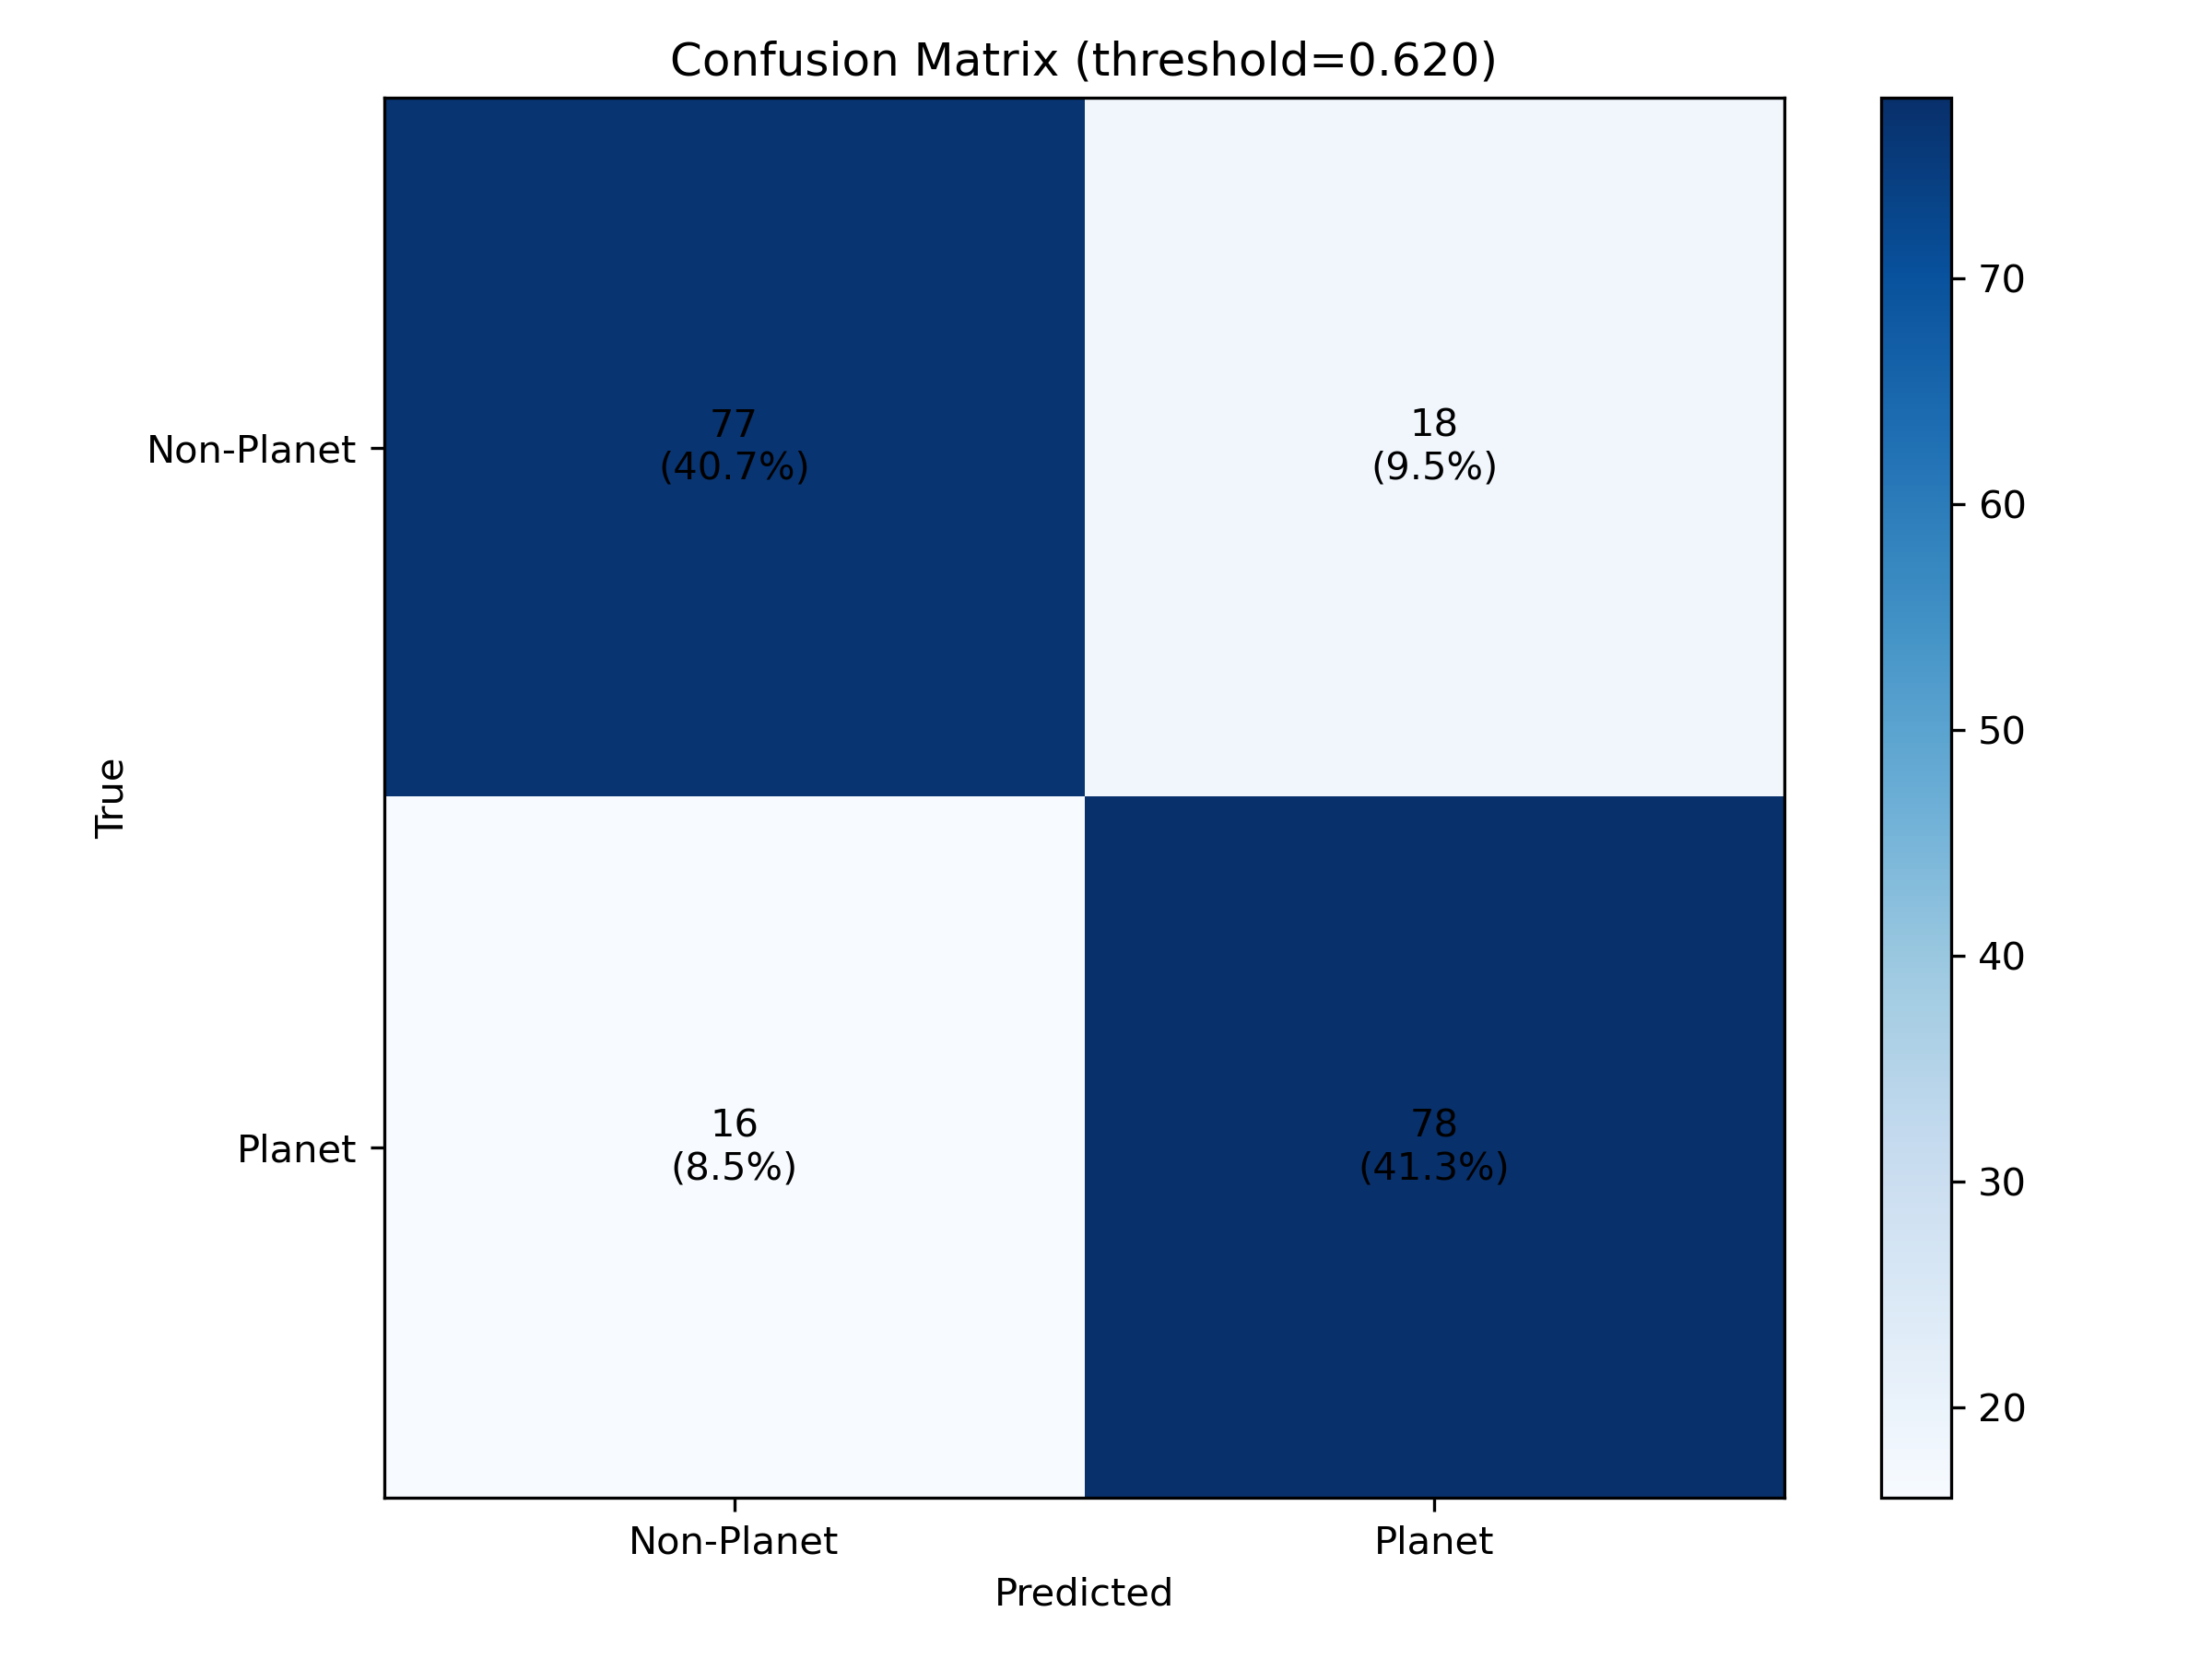

In [35]:
from IPython.display import Image, display
display(Image('confusion_matrix_final_config1_small.png'))

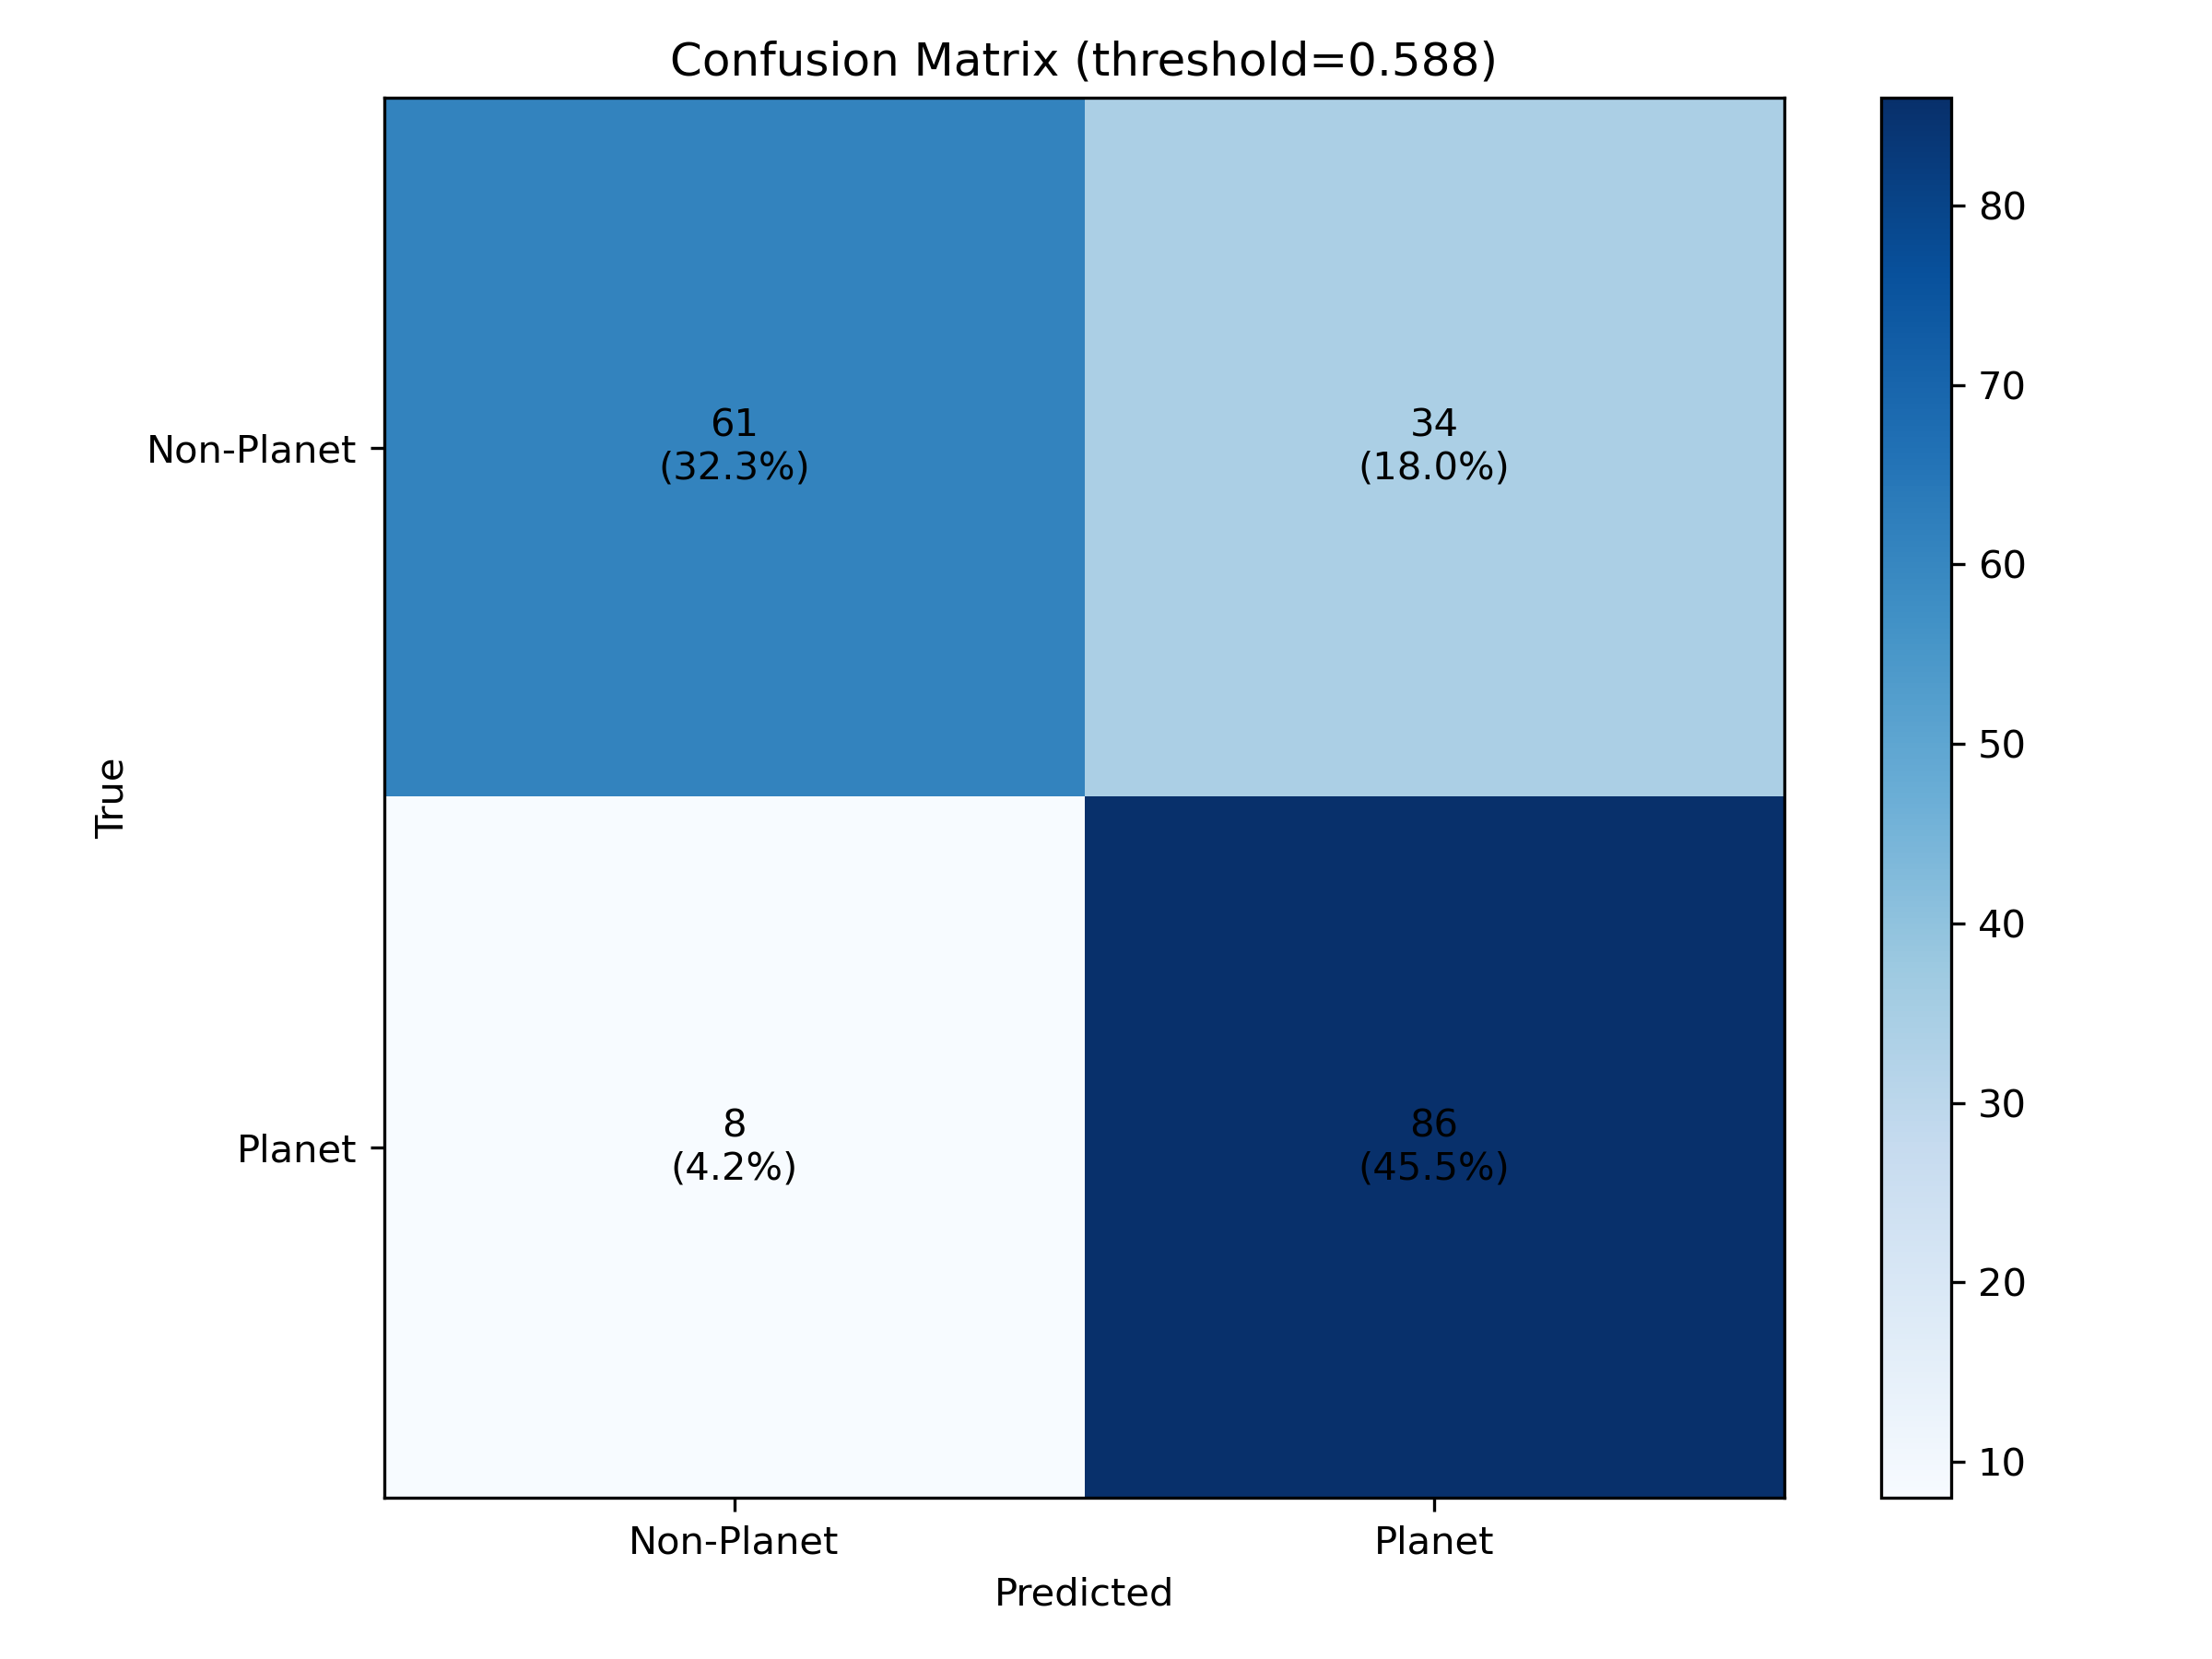

In [36]:
from IPython.display import Image, display
display(Image('confusion_matrix_final_config2_regularized.png'))

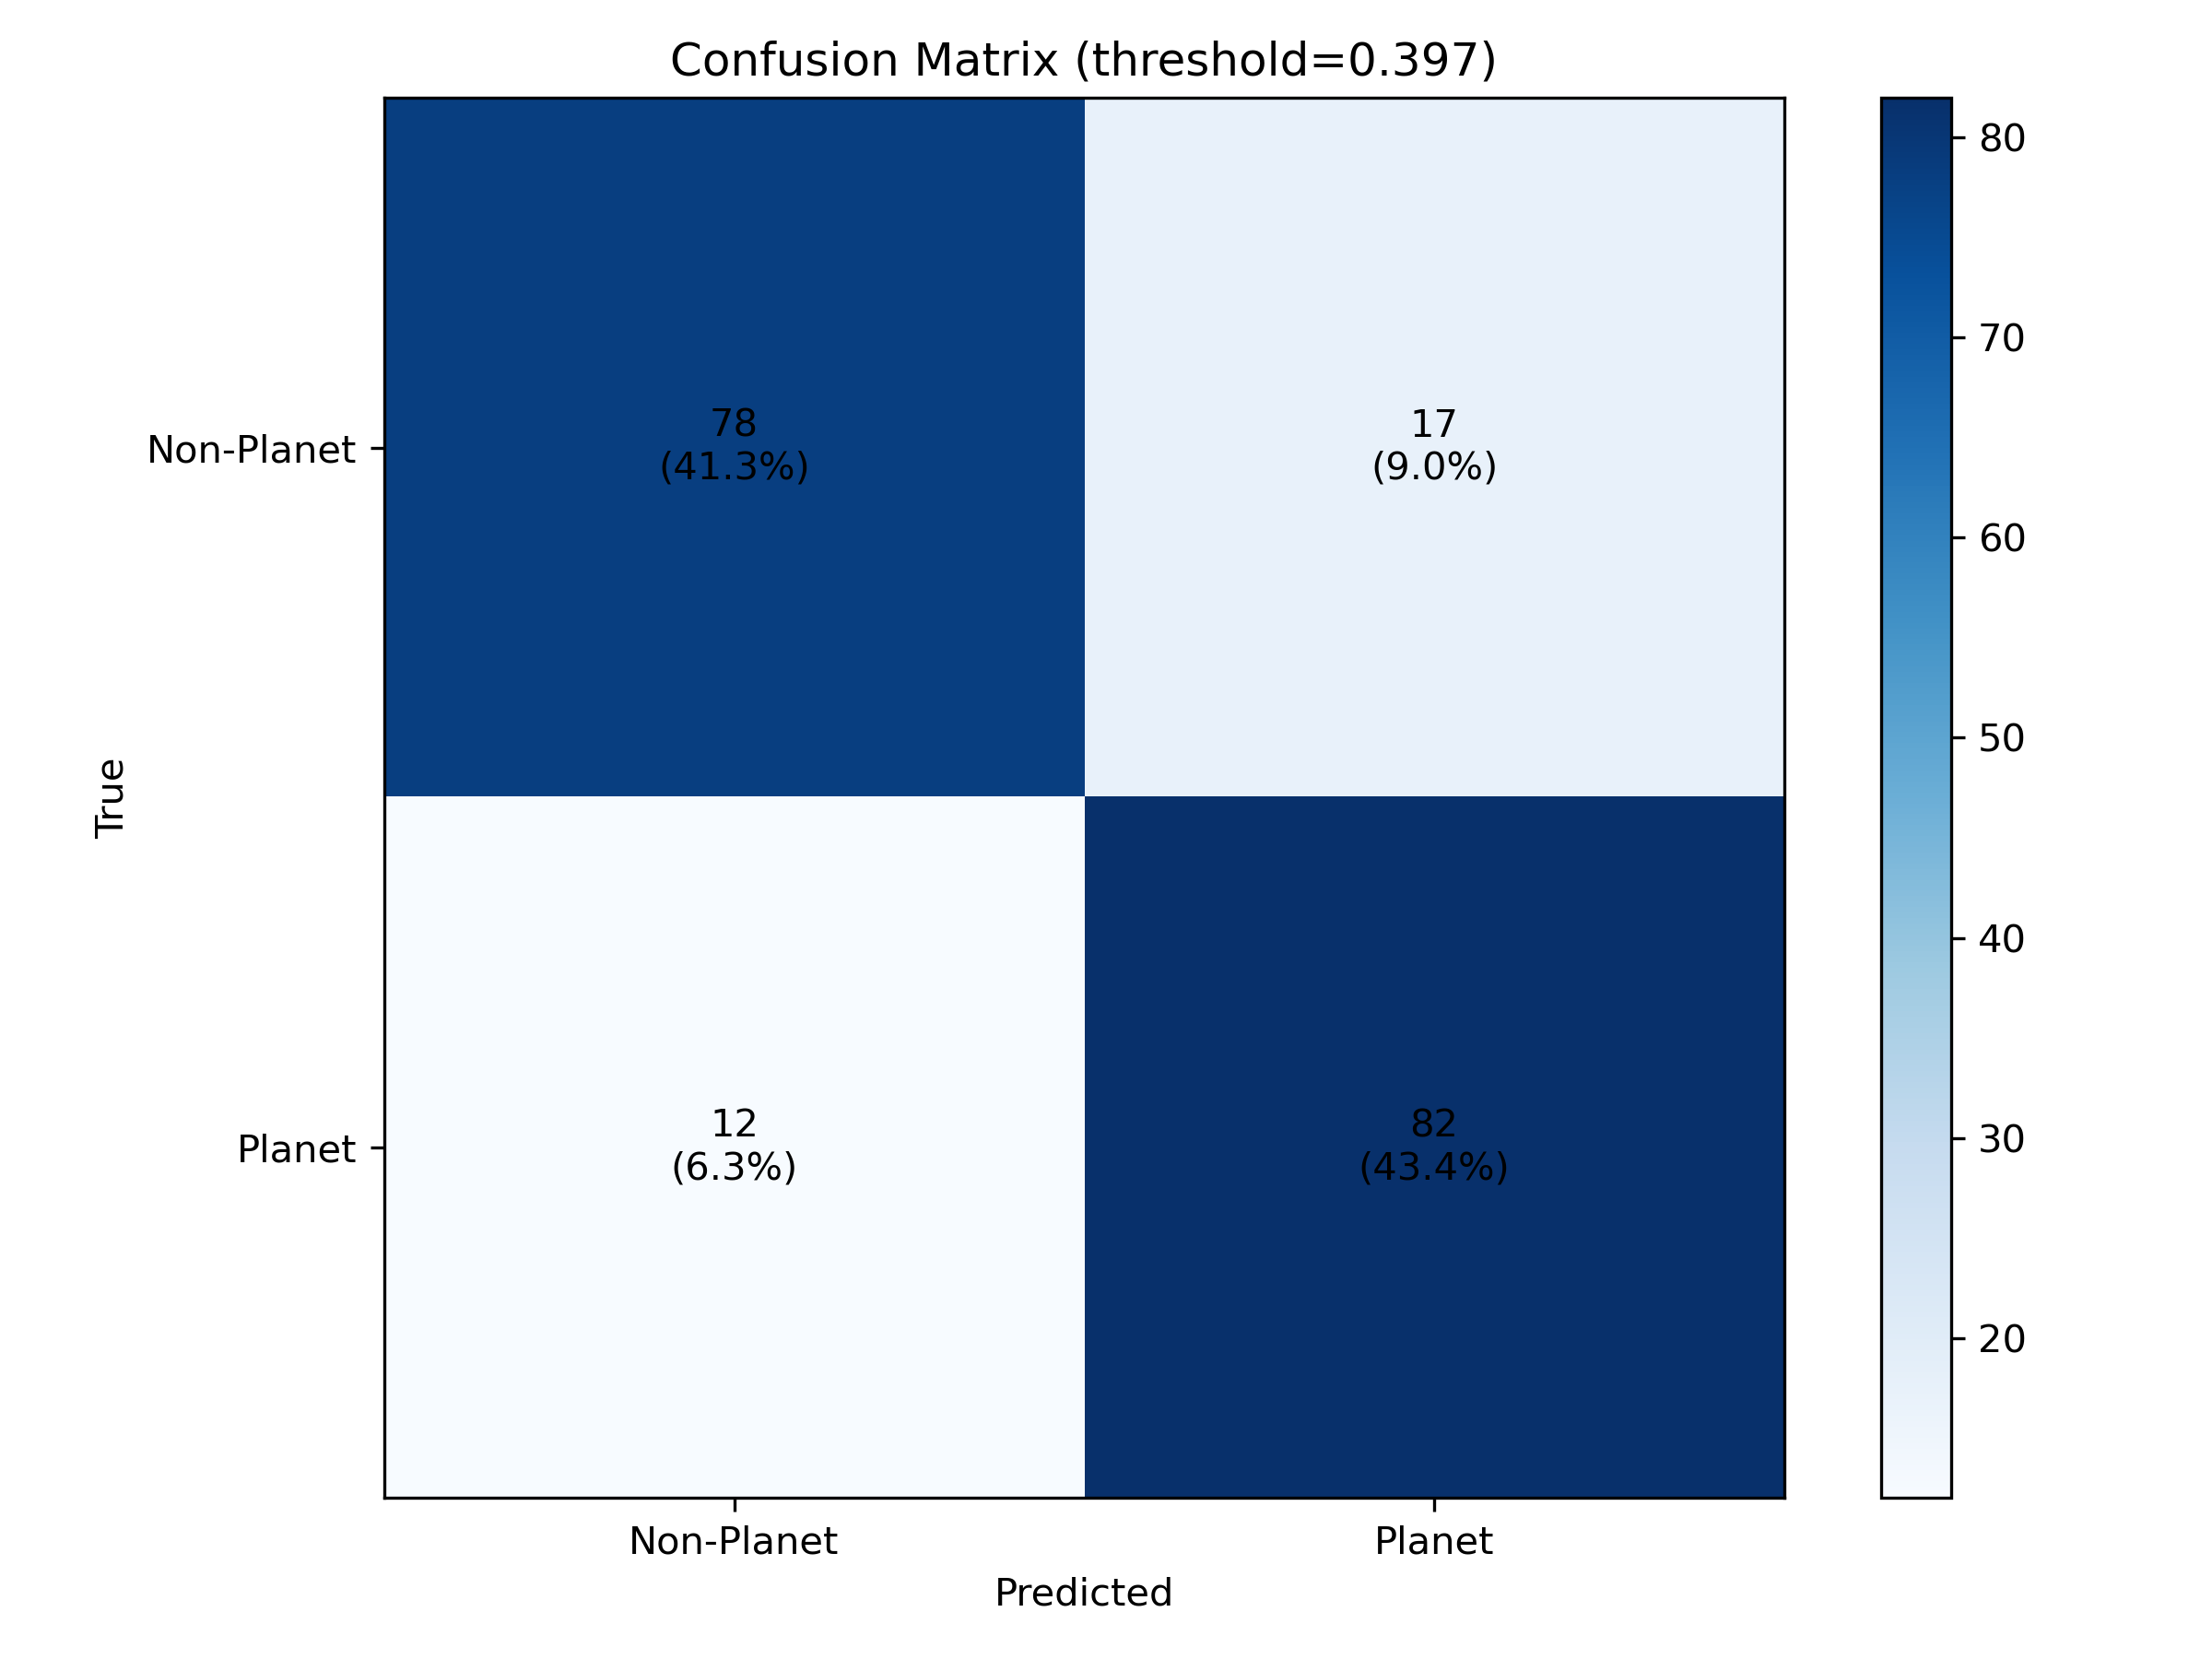

In [37]:
from IPython.display import Image, display
display(Image('confusion_matrix_final_config3_deeper.png'))